In [4]:
import pandas as pd
E = pd.read_parquet('data/processed/electricity.parquet')
print(E.columns)

Index(['time', 'consumption', 'generation', 'price_tl', 'temperature',
       'feels_like', 'humidity', 'cloud', 'wind', 'rain', 'holiday', 'year',
       'month', 'hour', 'dow', 'weekend'],
      dtype='object')


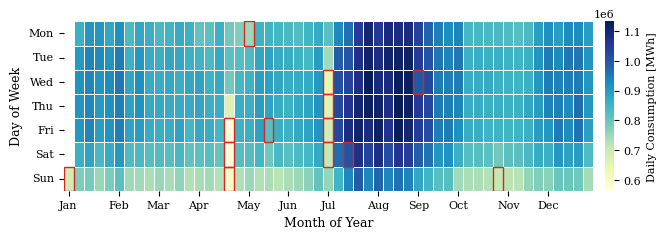

In [10]:
import matplotlib as mpl
import matplotlib.patches as patches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# ==========================================================
# 1. Cấu hình Matplotlib chuẩn bài báo khoa học (LaTeX/PDF)
# ==========================================================
mpl.rcParams["pdf.fonttype"] = 42
mpl.rcParams["ps.fonttype"] = 42
mpl.rcParams["font.family"] = "serif"
mpl.rcParams["font.size"] = 8

# ==========================================================
# 2. Xử lý và tính toán dữ liệu
# ==========================================================
df_2023 = E[E["year"] == 2023].copy()

# Tính tổng tiêu thụ hàng ngày và xác định ngày đó có phải là ngày lễ hay không
daily_df = (
    df_2023.groupby(df_2023["time"].dt.date)
    .agg(
        daily_consumption=("consumption", "sum"),
        is_holiday=("holiday", "max"),  # 1 nếu có giờ là lễ, 0 nếu không
    )
    .reset_index()
)
daily_df["time"] = pd.to_datetime(daily_df["time"])

# Tính chỉ số tuần và thứ trong tuần
first_day = pd.Timestamp("2023-01-01")
daily_df["week_idx"] = (
    (daily_df["time"] - first_day).dt.days + first_day.weekday()
) // 7
daily_df["dow"] = daily_df["time"].dt.weekday  # 0: Mon, ..., 6: Sun

# Tạo pivot table dữ liệu tiêu thụ
heatmap_matrix = daily_df.pivot(
    index="dow", columns="week_idx", values="daily_consumption"
)

all_weeks = np.arange(heatmap_matrix.columns.max() + 1)
heatmap_matrix = heatmap_matrix.reindex(index=range(7), columns=all_weeks)

# ==========================================================
# 3. Vẽ Heatmap
# ==========================================================
fig, ax = plt.subplots(figsize=(7.16, 2.2))

sns.heatmap(
    heatmap_matrix,
    cmap="YlGnBu",
    cbar_kws={
        "label": "Daily Consumption [MWh]",
        "pad": 0.02,
        "fraction": 0.025,
        "aspect": 18,
    },
    linewidths=0.5,
    linecolor="white",
    ax=ax,
)

# ==========================================================
# 4. Khoanh viền các ô là ngày lễ (Holiday)
# ==========================================================
# Lọc ra danh sách các ngày lễ trong năm 2023
holidays = daily_df[daily_df["is_holiday"] == 1]

for _, row in holidays.iterrows():
    # Tọa độ trong heatmap: x tương ứng week_idx, y tương ứng dow
    x = row["week_idx"]
    y = row["dow"]
    
    # Vẽ viền hình chữ nhật bao quanh ô ngày lễ
    rect = patches.Rectangle(
        (x, y),
        1,
        1,
        linewidth=1,
        edgecolor="#D62728",  # Viền đỏ nổi bật
        facecolor="none",
        zorder=5,
    )
    ax.add_patch(rect)

# ==========================================================
# 5. Tinh chỉnh trục & Nhãn chuẩn tiếng Anh học thuật
# ==========================================================
ax.set_yticks(np.arange(7) + 0.5)
ax.set_yticklabels(
    ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"],
    rotation=0,
    fontsize=8,
)
ax.set_ylabel("Day of Week", fontsize=9)

month_first_days = pd.date_range("2023-01-01", "2023-12-01", freq="MS")
month_week_positions = [
    ((d - first_day).days + first_day.weekday()) // 7
    for d in month_first_days
]
month_labels = [d.strftime("%b") for d in month_first_days]

ax.set_xticks([w + 0.5 for w in month_week_positions])
ax.set_xticklabels(month_labels, rotation=0, fontsize=8)
ax.set_xlabel("Month of Year", fontsize=9)

# ==========================================================
# 6. Xuất file PDF vector tối ưu lề cho LaTeX
# ==========================================================
plt.savefig(
    "heatmap_consumption_holidays_2023.pdf",
    format="pdf",
    bbox_inches="tight",
    pad_inches=0.02,
)
plt.show()
plt.close(fig)

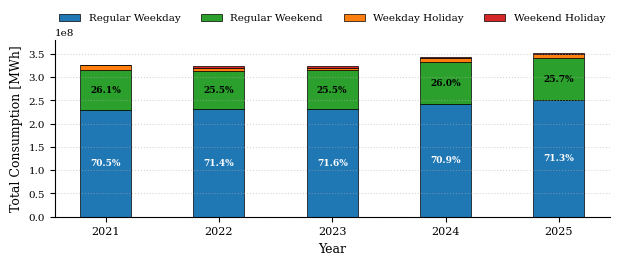

In [11]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# ==========================================================
# 1. Cấu hình Matplotlib chuẩn bài báo khoa học (LaTeX/PDF)
# ==========================================================
mpl.rcParams["pdf.fonttype"] = 42
mpl.rcParams["ps.fonttype"] = 42
mpl.rcParams["font.family"] = "serif"
mpl.rcParams["font.size"] = 8

# ==========================================================
# 2. Xử lý dữ liệu & Tính tổng tiêu thụ theo 4 loại ngày
# ==========================================================
years = [2021, 2022, 2023, 2024, 2025]
df_sub = E[E["year"].isin(years)].copy()

# Hàm phân loại 4 nhóm ngày
def classify_day_type(row):
    if row["holiday"] == 1 and row["weekend"] == 1:
        return "Weekend Holiday"
    elif row["holiday"] == 1 and row["weekend"] == 0:
        return "Weekday Holiday"
    elif row["holiday"] == 0 and row["weekend"] == 1:
        return "Regular Weekend"
    else:
        return "Regular Weekday"

df_sub["day_type"] = df_sub.apply(classify_day_type, axis=1)

day_types = [
    "Regular Weekday",
    "Regular Weekend",
    "Weekday Holiday",
    "Weekend Holiday",
]

palette = {
    "Regular Weekday": "#1f77b4",  # Xanh dương
    "Regular Weekend": "#2ca02c",  # Xanh lá
    "Weekday Holiday": "#ff7f0e",  # Cam
    "Weekend Holiday": "#d62728",  # Đỏ
}

# Tổng hợp sản lượng tiêu thụ điện (consumption) theo từng năm và loại ngày
agg_df = (
    df_sub.groupby(["year", "day_type"])["consumption"]
    .sum()
    .reset_index()
)

# Chuyển đổi thành ma trận pivot: Dòng là Năm, Cột là 4 loại ngày
pivot_df = agg_df.pivot(index="year", columns="day_type", values="consumption").fillna(0)
pivot_df = pivot_df.reindex(index=years, columns=day_types)

# ==========================================================
# 3. Vẽ biểu đồ cột chồng với tỷ lệ ngang dẹt (Panoramic Ratio)
# ==========================================================
# Kích thước: Ngang 7.16 in (chuẩn 2 cột), Cao 2.3 in (~ tỷ lệ 3.1 : 1)
fig, ax = plt.subplots(figsize=(7.16, 2.3))

x = np.arange(len(years))
width = 0.45  # Độ rộng cột cân đối
bottom = np.zeros(len(years))

for dt in day_types:
    values = pivot_df[dt].values
    bars = ax.bar(
        x,
        values,
        bottom=bottom,
        width=width,
        label=dt,
        color=palette[dt],
        edgecolor="black",
        linewidth=0.5,
    )

    # Hiển thị tỷ lệ đóng góp (%) trực tiếp vào các phần cột đủ lớn
    for i, val in enumerate(values):
        total_year = pivot_df.iloc[i].sum()
        pct = (val / total_year) * 100
        # Chỉ vẽ nhãn nếu tỷ lệ >= 4% để tránh bị dính chữ
        if pct >= 4.0:
            y_pos = bottom[i] + val / 2
            ax.text(
                x[i],
                y_pos,
                f"{pct:.1f}%",
                ha="center",
                va="center",
                color="white" if dt in ["Regular Weekday", "Weekend Holiday"] else "black",
                fontsize=6.5,
                weight="bold",
            )

    bottom += values

# ==========================================================
# 4. Tinh chỉnh trục & Nhãn (Font size chuẩn 6.5 - 9 pt)
# ==========================================================
ax.set_xticks(x)
ax.set_xticklabels(years, fontsize=8)
ax.set_xlabel("Year", fontsize=9)
ax.set_ylabel("Total Consumption [MWh]", fontsize=9)
ax.tick_params(axis="y", labelsize=7.5)

# Đặt định dạng hiển thị trục Y theo ký hiệu khoa học gọn gàng
ax.yaxis.get_offset_text().set_fontsize(7.5)

# Mở rộng nhẹ đỉnh trục tung để không bị cấn sát viền
ax.set_ylim(0, bottom.max() * 1.08)

sns.despine(ax=ax)
ax.grid(axis="y", linestyle=":", alpha=0.5)

# Bố trí Legend dạng hàng ngang sát trên đỉnh
ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, 1.20),
    ncol=4,
    frameon=False,
    fontsize=7.5,
)

# ==========================================================
# 5. Xuất file PDF vector tối ưu lề cho LaTeX
# ==========================================================
plt.savefig(
    "stacked_barchart_consumption_daytypes_5years.pdf",
    format="pdf",
    bbox_inches="tight",
    pad_inches=0.02,
)

plt.show()

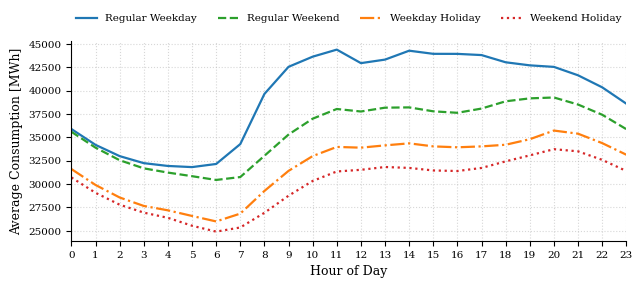

In [12]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# ==========================================================
# 1. Cấu hình Matplotlib chuẩn bài báo khoa học (LaTeX/PDF)
# ==========================================================
mpl.rcParams["pdf.fonttype"] = 42
mpl.rcParams["ps.fonttype"] = 42
mpl.rcParams["font.family"] = "serif"
mpl.rcParams["font.size"] = 8  # Base font size: 8 pt

# ==========================================================
# 2. Xử lý dữ liệu & Phân loại 4 nhóm ngày
# ==========================================================
years = [2021, 2022, 2023, 2024, 2025]
df_plot = E[E["year"].isin(years)].copy()

# Hàm gán nhãn 4 loại ngày
def classify_day_type(row):
    if row["holiday"] == 1 and row["weekend"] == 1:
        return "Weekend Holiday"
    elif row["holiday"] == 1 and row["weekend"] == 0:
        return "Weekday Holiday"
    elif row["holiday"] == 0 and row["weekend"] == 1:
        return "Regular Weekend"
    else:
        return "Regular Weekday"

df_plot["day_type"] = df_plot.apply(classify_day_type, axis=1)

# Thứ tự nhóm ngày, màu sắc và kiểu nét vẽ nhất quán
day_types = [
    "Regular Weekday",
    "Regular Weekend",
    "Weekday Holiday",
    "Weekend Holiday",
]

palette = {
    "Regular Weekday": "#1f77b4",  # Xanh dương
    "Regular Weekend": "#2ca02c",  # Xanh lá cây
    "Weekday Holiday": "#ff7f0e",  # Cam
    "Weekend Holiday": "#d62728",  # Đỏ
}

style_dict = {
    "Regular Weekday": "-",
    "Regular Weekend": "--",
    "Weekday Holiday": "-.",
    "Weekend Holiday": ":",
}

# Tính giá trị trung bình theo từng giờ cho 4 nhóm ngày
hourly_avg = (
    df_plot.groupby(["day_type", "hour"])["consumption"]
    .mean()
    .reset_index()
)

# ==========================================================
# 3. Vẽ biểu đồ 1 khung nhìn (Panoramic Single Plot)
# ==========================================================
# Chiều ngang 7.16 inch (chuẩn 2 cột LaTeX), chiều cao 2.6 inch
fig, ax = plt.subplots(figsize=(7.16, 2.6))

for dt in day_types:
    dt_data = hourly_avg[hourly_avg["day_type"] == dt]
    if not dt_data.empty:
        ax.plot(
            dt_data["hour"],
            dt_data["consumption"],
            label=dt,
            color=palette[dt],
            linestyle=style_dict[dt],
            linewidth=1.6,
        )

# ==========================================================
# 4. Tinh chỉnh trục & Nhãn (Font size chuẩn 6.5 - 9 pt)
# ==========================================================
ax.set_xlim(0, 23)
ax.set_xticks(range(0, 24, 1))  # Hiển thị đủ 24 giờ
ax.set_xticklabels(range(0, 24, 1), fontsize=7.5)
ax.set_xlabel("Hour of Day", fontsize=9)

ax.set_ylabel("Average Consumption [MWh]", fontsize=9)
ax.tick_params(axis="y", labelsize=7.5)
ax.yaxis.get_offset_text().set_fontsize(7.5)

# Lược bỏ viền trên và bên phải
sns.despine(ax=ax)
ax.grid(True, linestyle=":", alpha=0.5)

# Bố trí Legend dạng hàng ngang sát trên đỉnh
ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, 1.18),
    ncol=4,
    frameon=False,
    fontsize=7.5,
)

# ==========================================================
# 5. Xuất file PDF vector tối ưu lề cho LaTeX
# ==========================================================
plt.savefig(
    "lineplot_hourly_consumption_4_daytypes_single.pdf",
    format="pdf",
    bbox_inches="tight",
    pad_inches=0.02,
)

plt.show()